<div style="border-top: 1px solid rgba(128, 128, 128, 0.45); padding-top: 10px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65;">Paper overview</span></div>

## <span style="font-family: Newsreader, Georgia, serif; font-size: 34px; font-weight: 400;">1. Introduction</span>

### 1.1 Research question

<div style="border-top: 3px solid #ac543f; background: rgba(172, 84, 63, 0.07); padding: 12px 18px 14px 18px;"><div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65; margin-bottom: 6px;">Research question</div><div style="font-family: Newsreader, Georgia, serif; font-size: 21px; line-height: 1.4;">Can a classifier's attention explain each decision in concepts people understand, rather than raw input features, so that the explanation is both convincing to people and true to how the model actually decided?</div></div>

### 1.2 Existing approaches, and where they fall short

<div><div style="display: inline-block; vertical-align: top; width: 31%; margin-right: 3%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 2px;">Post-hoc saliency</div><div style="font-size: 13.5px; opacity: 0.7; margin-bottom: 6px;">Grad-CAM, LIME, SHAP</div><div style="font-size: 15px; line-height: 1.5;">Score pixels or input features after training to show where a black-box model looked.</div><div style="font-size: 15px; line-height: 1.5; margin-top: 6px;"><b>Falls short:</b> the explanation is fitted from outside, so nothing guarantees that it matches the computation, and pixels are not the concepts people reason with.</div></div><div style="display: inline-block; vertical-align: top; width: 31%; margin-right: 3%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 2px;">Attention as explanation</div><div style="font-size: 13.5px; opacity: 0.7; margin-bottom: 6px;">attention weights over patches or words</div><div style="font-size: 15px; line-height: 1.5;">Read the model's own attention weights to see which inputs it used.</div><div style="font-size: 15px; line-height: 1.5; margin-top: 6px;"><b>Falls short:</b> later layers mix the attended features, so a high weight need not mean a large effect on the decision; hence &ldquo;attention is not explanation&rdquo; (Jain &amp; Wallace, 2019).</div></div><div style="display: inline-block; vertical-align: top; width: 31%; border-top: 3px solid #4978a7; padding-top: 8px;"><div style="font-family: Newsreader, Georgia, serif; font-size: 22px; margin-bottom: 2px;">Concept and prototype models</div><div style="font-size: 13.5px; opacity: 0.7; margin-bottom: 6px;">TCAV, ProtoPNet, SENN</div><div style="font-size: 15px; line-height: 1.5;">Explain with human-defined concepts or with learned part prototypes.</div><div style="font-size: 15px; line-height: 1.5; margin-top: 6px;"><b>Falls short:</b> concepts are probed after training or prototypes are learned apart from the decision, so faithfulness is not guaranteed; part prototypes cannot express whole-object concepts such as size or shape, and SENN does not localize its concepts.</div></div></div>

### 1.3 The Concept Transformer: attention over named concepts

The Concept Transformer replaces the classifier head: every token attends over learned concept embeddings, and the class scores are read straight from that attention.

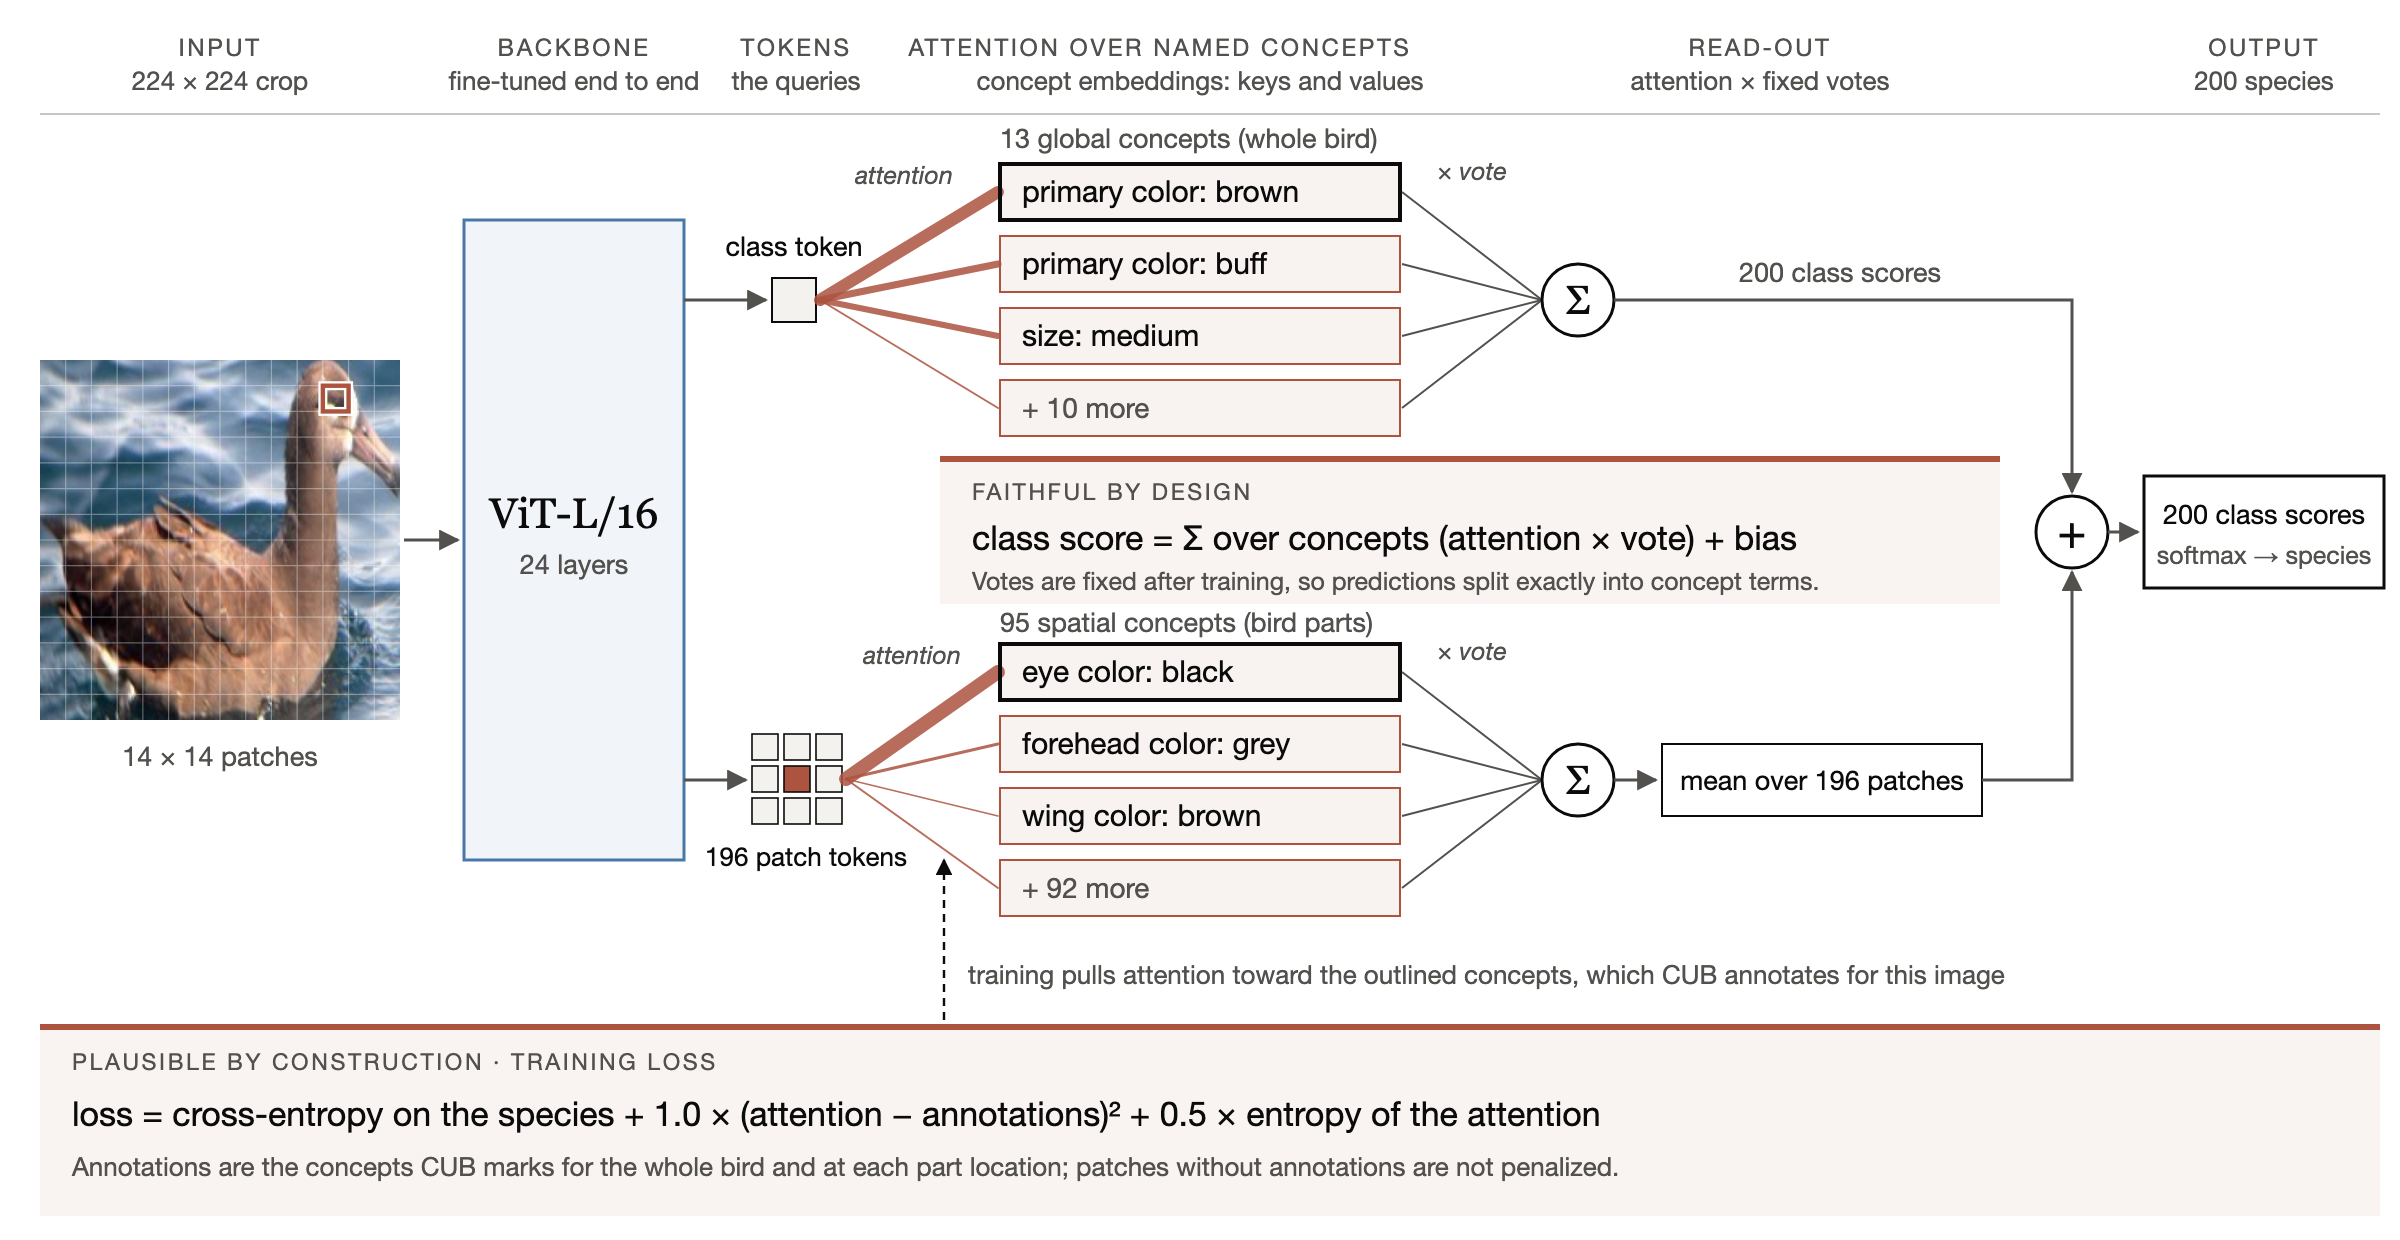

<div style="font-size: 13.5px; line-height: 1.45; opacity: 0.8; margin: 4px 0 10px 0; max-width: 960px;"><b>Figure 1.1</b> The model as the repository builds it for CUB-200-2011 (<code>cub_cvit</code> in <code>concept_transformer/ctc/vit.py</code>), drawn on test image 3. The two shaded boxes are the paper's two claims. Line weights only illustrate attention; Figures 1.2 and 1.3 show what the trained model computed for this image.</div>

<details><summary style="cursor: pointer; font-size: 15px;"><b>Backup:</b> the read-out as an equation, and how the 108 concepts were chosen</summary>

$$\text{score}_k(x) \;=\; \sum_{c} \gamma_c(x)\,\beta_{ck} \;+\; b_k, \qquad \gamma_c(x) \;=\; \frac{1}{P}\sum_{p=1}^{P} \alpha_{pc}(x)$$

$\alpha_{pc}$ is the attention of patch $p$ on concept $c$, $\gamma_c$ its average over the $P$ patches (for a global concept, the class token's attention), and $\beta_{ck}$ the fixed vote of concept $c$ for class $k$: its value vector times the output projection (the paper's Equation 2). With several attention heads, the sum runs over head and concept pairs.

The 13 global and 95 spatial concepts are the CUB attributes, out of 312, present in at least 45% of a species' images and in at least 9 species.

</details>

### 1.4 The method on one test image

Both figures follow one CUB test image through the trained model. They read the attention and per-concept contributions that `scripts/visualize_test_explanations.py` cached from our disjoint run's selected checkpoint, so they draw instantly and need no GPU.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; set <code>EXAMPLE_IMAGE_ID</code> to 3, 190 or 622 (predicted correctly) or 434, 1593 or 2904 (wrong) and re-run</span></div>

In [1]:
# Figure 1.2: one test image as tokens, and each token's attention over named concepts.
EXAMPLE_IMAGE_ID = 3  # a cached test image: 3, 190, 622 (predicted correctly) or 434, 1593, 2904 (wrong)
PATCHES_SHOWN = 4     # annotated patches drawn as table columns

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

INK, MUTED = "#0b0b0b", "#52514e"
ATTENTION = LinearSegmentedColormap.from_list(  # white to terracotta: the darker the cell, the more attention
    "attention", ["#ffffff", "#f2d9d1", "#dca592", "#c27660", PALETTE["accent"], "#6b3225"])
ATTENTION.set_bad("#f3f2ee")  # cells a token cannot attend to: patches see no global concepts, and vice versa

report = json.loads((ARTIFACT_DIR / "examples.json").read_text())
arrays = np.load(ARTIFACT_DIR / "selected_examples.npz")
saved_ids = [sample["image_id"] for sample in report["examples"]]
assert EXAMPLE_IMAGE_ID in saved_ids, "Choose EXAMPLE_IMAGE_ID from {}".format(saved_ids)
index = saved_ids.index(EXAMPLE_IMAGE_ID)
example = report["examples"][index]


def concept_label(attribute):
    """'has_eye_color::black' -> 'eye color: black'; size ranges are dropped."""
    family, value = attribute.replace("has_", "").split("::")
    return "{}: {}".format(family.replace("_", " "), value.split("_(")[0].replace("_", " "))


global_names = [concept_label(name) for name in report["global_attributes"]]
spatial_names = [concept_label(name) for name in report["spatial_attributes"]]
image = arrays["images"][index]                         # the 224 x 224 test crop, de-normalized
spatial_attention = arrays["spatial_attention"][index]  # (patches, spatial concepts); each row sums to 1
spatial_targets = arrays["spatial_targets"][index]      # 1 = annotated there; all-NaN row = no annotation
global_attention = arrays["global_attention"][index]    # (global concepts,); sums to 1
global_targets = arrays["global_targets"][index]
n_patches, n_spatial = spatial_attention.shape
grid = int(round(n_patches ** 0.5))
patch_size = image.shape[0] / grid
annotated = [int(p) for p in np.flatnonzero(~np.isnan(spatial_targets).all(axis=1))]


def best_annotated_concept(patch):
    concepts = np.flatnonzero(spatial_targets[patch] == 1)
    return int(concepts[np.argmax(spatial_attention[patch, concepts])])


# Columns: for each concept family, the annotated patch whose attention best matches its annotation.
shown, families = [], set()
for patch in sorted(annotated, key=lambda p: -spatial_attention[p, best_annotated_concept(p)]):
    family = spatial_names[best_annotated_concept(patch)].split(":")[0]
    if family not in families:
        shown.append(patch)
        families.add(family)
    if len(shown) == PATCHES_SHOWN:
        break
shown.sort()

# Rows: each shown patch's annotated concepts (up to 3) and its most-attended concept,
# then the whole-image token's annotated global concepts and its top 3.
spatial_rows = []
for patch in shown:
    marked = np.flatnonzero(spatial_targets[patch] == 1)
    marked = marked[np.argsort(-spatial_attention[patch, marked])][:3]
    for concept in list(marked) + [np.argmax(spatial_attention[patch])]:
        if int(concept) not in spatial_rows:
            spatial_rows.append(int(concept))
global_rows = sorted({int(c) for c in np.flatnonzero(global_targets == 1)}
                     | {int(c) for c in np.argsort(-global_attention)[:3]},
                     key=lambda c: -global_attention[c])
n_spatial_rows = len(spatial_rows)
table = np.full((n_spatial_rows + len(global_rows), len(shown) + 1), np.nan)
is_target = np.zeros(table.shape, dtype=bool)
for column, patch in enumerate(shown):
    table[:n_spatial_rows, column] = spatial_attention[patch, spatial_rows]
    is_target[:n_spatial_rows, column] = spatial_targets[patch, spatial_rows] == 1
table[n_spatial_rows:, -1] = global_attention[global_rows]
is_target[n_spatial_rows:, -1] = global_targets[global_rows] == 1
n_rows, n_columns = table.shape


def outline(ax, x, y, width, height):
    """Annotation outline: ink inside a white halo, readable on light and dark pixels."""
    for color, linewidth in [("white", 3.2), (INK, 1.6)]:
        ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor=color,
                               linewidth=linewidth, zorder=3))


def patch_center(patch):
    row, col = divmod(patch, grid)
    return np.array([(col + 0.5) * patch_size, (row + 0.5) * patch_size])


def badge_spot(patch, placed):
    """Near the patch and inside the image, clear of other badges and, if possible, of every outline."""
    candidates = [patch_center(patch) + 1.7 * patch_size * np.array(offset) for offset in
                  [(-1, 0), (0, -1), (1, 0), (0, 1), (-0.8, -0.8), (0.8, -0.8), (-0.8, 0.8), (0.8, 0.8)]]
    candidates = [spot for spot in candidates if (spot >= 0.6 * patch_size).all()
                  and (spot <= image.shape[0] - 0.6 * patch_size).all()]
    for avoid in [annotated, shown]:
        for spot in candidates:
            if all(np.abs(spot - patch_center(p)).max() > 1.05 * patch_size for p in avoid) and \
                    all(np.abs(spot - other).max() > 1.3 * patch_size for other in placed):
                return spot
    return candidates[0]


def patch_edge_toward(patch, spot):
    """Point on the patch's border facing the badge, where its leader line ends."""
    direction = spot - patch_center(patch)
    return patch_center(patch) + direction * 0.5 * patch_size / np.abs(direction).max()


with plt.rc_context({"axes.grid": False, "font.size": 10.5, "text.color": INK,
                     "xtick.color": INK, "ytick.color": INK}):
    figure, (ax_image, ax_table) = plt.subplots(
        1, 2, figsize=(12.5, 6.2), gridspec_kw={"width_ratios": [1, 1.25]}, constrained_layout=True)

    # (a) The image as tokens: the patch grid, annotated part locations, numbered table columns.
    ax_image.imshow(image)
    for k in range(1, grid):
        ax_image.axhline(k * patch_size - 0.5, color="white", linewidth=0.4, alpha=0.35)
        ax_image.axvline(k * patch_size - 0.5, color="white", linewidth=0.4, alpha=0.35)
    for patch in annotated:
        row, col = divmod(patch, grid)
        outline(ax_image, col * patch_size - 0.5, row * patch_size - 0.5, patch_size, patch_size)
    placed = []
    for number, patch in enumerate(shown, start=1):
        spot = badge_spot(patch, placed)
        placed.append(spot)
        edge = patch_edge_toward(patch, spot)
        for color, linewidth in [("white", 2.6), (INK, 1.0)]:
            ax_image.plot([edge[0], spot[0]], [edge[1], spot[1]], color=color, linewidth=linewidth, zorder=3.5)
        ax_image.text(spot[0], spot[1], str(number), ha="center", va="center", fontsize=10.5,
                      fontweight="bold", zorder=4,
                      bbox={"boxstyle": "circle,pad=0.25", "facecolor": "white", "edgecolor": INK,
                            "linewidth": 0.8})
    ax_image.set_xlim(-0.5, image.shape[1] - 0.5)
    ax_image.set_ylim(image.shape[0] - 0.5, -0.5)
    ax_image.set_xticks([])
    ax_image.set_yticks([])
    ax_image.set_title("(a) Test image {} · {}".format(example["image_id"], example["true_class"]),
                       loc="left", fontsize=12)
    ax_image.set_xlabel("{0} × {0} = {1} patch tokens + 1 whole-image token\n"
                        "outlined: the {2} patches where CUB annotates a bird part".format(
                            grid, n_patches, len(annotated)), color=MUTED, fontsize=10)

    # (b) Each token's attention over named concepts; outlined cells are the training target.
    cells = ax_table.imshow(np.ma.masked_invalid(table), cmap=ATTENTION, vmin=0, vmax=1, aspect="auto")
    for position in np.arange(-0.5, n_rows):
        ax_table.plot([-0.5, n_columns - 0.5], [position, position], color="white", linewidth=2)
    for position in np.arange(-0.5, n_columns):
        ax_table.plot([position, position], [-0.5, n_rows - 0.5], color="white", linewidth=2)
    for (r, c), value in np.ndenumerate(table):
        if np.isfinite(value) and value >= 0.05:
            ax_table.text(c, r, "{:.2f}".format(value), ha="center", va="center", fontsize=9.5,
                          color="white" if value >= 0.7 else INK)
        if is_target[r, c]:
            outline(ax_table, c - 0.5, r - 0.5, 1, 1)
    ax_table.plot([-0.5, n_columns - 0.5], [n_spatial_rows - 0.5] * 2, color=INK, linewidth=1.0)
    ax_table.text(n_columns - 1, (n_spatial_rows - 1) / 2, "spatial concepts:\nattended by\npatch tokens",
                  ha="center", va="center", fontsize=8.5, color=MUTED)
    ax_table.text((n_columns - 2) / 2, n_spatial_rows + (len(global_rows) - 1) / 2,
                  "global concepts: attended by the whole-image token", ha="center", va="center",
                  fontsize=8.5, color=MUTED)
    ax_table.set_xlim(-0.5, n_columns - 0.5)
    ax_table.set_ylim(n_rows - 0.5, -0.5)
    ax_table.set_xticks(range(n_columns))
    ax_table.set_xticklabels(["patch {}".format(n) for n in range(1, len(shown) + 1)] + ["whole\nimage"])
    ax_table.xaxis.tick_top()
    ax_table.set_yticks(range(n_rows))
    ax_table.set_yticklabels([spatial_names[c] for c in spatial_rows] + [global_names[c] for c in global_rows])
    ax_table.tick_params(length=0)
    ax_table.set_title("(b) Attention of each token over named concepts", loc="left", fontsize=12)
    for ax in (ax_image, ax_table):
        for spine in ax.spines.values():
            spine.set_visible(False)
    colorbar = figure.colorbar(cells, ax=ax_table, orientation="horizontal", fraction=0.04, pad=0.02,
                               shrink=0.55, aspect=30)
    colorbar.outline.set_visible(False)
    colorbar.ax.tick_params(labelsize=9, colors=MUTED, length=0)
    colorbar.set_label("attention weight · each token's weights sum to 1 over its {} spatial or {} global concepts"
                       .format(n_spatial, len(global_names)), color=MUTED, fontsize=9)
    ax_table.legend(handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor=INK, linewidth=1.6)],
                    labels=["annotated in CUB at that location: the training target"], loc="upper left",
                    bbox_to_anchor=(0, -0.005), frameon=False, fontsize=9, handlelength=1.2)
    figure.suptitle("Every token spreads its attention over named concepts; training pulls it toward "
                    "CUB's annotations", x=0.01, ha="left", fontsize=13)
    plt.show()
caption("<b>Figure 1.2</b> How the model reads test image {}. (a) The crop as {} patch tokens. Outlined patches carry "
        "CUB part annotations; numbers mark the table's columns, which are, per concept family, the annotated patch "
        "whose attention best matches its annotation. (b) Each column is one token's attention: patch tokens attend "
        "only over spatial concepts, the whole-image token only over global ones. Outlined cells are what CUB "
        "annotates at that location, the target the explanation loss pulls attention toward. Values are cached "
        "from the disjoint run's selected checkpoint.".format(EXAMPLE_IMAGE_ID, n_patches))

NameError: name 'PALETTE' is not defined

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; set <code>EXAMPLE_IMAGE_ID</code> to the image shown in Figure 1.2; <code>CONCEPTS_SHOWN</code> sets how many concepts get their own bar</span></div>

In [ ]:
# Figure 1.3: the same prediction split into per-concept contributions that add up to the model's score gap.
EXAMPLE_IMAGE_ID = 3  # the image from Figure 1.2: 3, 190, 622 (predicted correctly) or 434, 1593, 2904 (wrong)
CONCEPTS_SHOWN = 6    # largest contributions drawn one by one; the remaining concepts share one bar

from matplotlib.patches import Patch

INK, MUTED = "#0b0b0b", "#52514e"
report = json.loads((ARTIFACT_DIR / "examples.json").read_text())
arrays = np.load(ARTIFACT_DIR / "selected_examples.npz")
saved_ids = [sample["image_id"] for sample in report["examples"]]
assert EXAMPLE_IMAGE_ID in saved_ids, "Choose EXAMPLE_IMAGE_ID from {}".format(saved_ids)
index = saved_ids.index(EXAMPLE_IMAGE_ID)
example = report["examples"][index]


def concept_label(attribute):
    """'has_eye_color::black' -> 'eye color: black'; size ranges are dropped."""
    family, value = attribute.replace("has_", "").split("::")
    return "{}: {}".format(family.replace("_", " "), value.split("_(")[0].replace("_", " "))


# The cached contributions list the 13 global concepts, then the 95 spatial ones, each summed over heads.
concept_names = (["G · " + concept_label(name) for name in report["global_attributes"]]
                 + ["S · " + concept_label(name) for name in report["spatial_attributes"]])
contributions = arrays["contributions"][index]  # (concepts, classes)
logits, bias = arrays["logits"][index], arrays["bias"]
assert contributions.shape[0] == len(concept_names)
predicted, comparison = example["predicted_label"], example["comparison_label"]
predicted_name, comparison_name = example["predicted_class"], example["comparison_class"]

gap_by_concept = contributions[:, predicted] - contributions[:, comparison]
order = np.argsort(-np.abs(gap_by_concept))
steps = list(gap_by_concept[order[:CONCEPTS_SHOWN]]) + [
    gap_by_concept[order[CONCEPTS_SHOWN:]].sum(), bias[predicted] - bias[comparison]]
labels = [concept_names[c] for c in order[:CONCEPTS_SHOWN]] + [
    "{} other concepts".format(len(order) - CONCEPTS_SHOWN), "classifier biases"]
score_gap = logits[predicted] - logits[comparison]
largest_error = np.abs(contributions.sum(axis=0) + bias - logits).max()  # over all classes
assert abs(sum(steps) - score_gap) < 1e-3, "The contributions should rebuild the score gap."

with plt.rc_context({"axes.grid": False, "font.size": 10.5, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": INK}):
    figure, ax = plt.subplots(figsize=(10.5, 4.9), constrained_layout=True)
    starts = np.concatenate([[0.0], np.cumsum(steps)[:-1]])
    reach = np.concatenate([[0.0, score_gap], np.cumsum(steps)])
    pad = 0.04 * (reach.max() - reach.min())
    ax.barh(range(len(steps)), steps, left=starts, height=0.55,
            color=[PALETTE["accent"] if step >= 0 else PALETTE["neg"] for step in steps])
    ax.barh(len(steps), score_gap, height=0.55, color=INK)
    for row, (start, step) in enumerate(zip(starts, steps)):
        end = start + step
        ax.plot([end, end], [row + 0.28, row + 0.72], color=MUTED, linewidth=0.8)  # link to the next bar
        ax.text(end + (pad if step >= 0 else -pad), row, "{:+.2f}".format(step),
                ha="left" if step >= 0 else "right", va="center", fontsize=9.5)
    ax.text(score_gap + (pad if score_gap >= 0 else -pad), len(steps), "{:.2f}".format(score_gap),
            ha="left" if score_gap >= 0 else "right", va="center", fontsize=9.5, fontweight="bold")
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_xlim(reach.min() - 4 * pad, reach.max() + 4 * pad)
    ax.set_yticks(range(len(steps) + 1))
    ax.set_yticklabels(labels + ["score gap in the model's output"])
    ax.invert_yaxis()
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.set_xlabel("contribution to  score({})  −  score({})".format(predicted_name, comparison_name),
                  color=MUTED)
    question = "Why {} ({:.0%})".format(predicted_name, example["predicted_probability"])
    question += " rather than {}?".format(comparison_name) if example["correct"] else \
        " instead of the true class, {}?".format(comparison_name)
    ax.set_title(question, loc="left", fontsize=11.5)
    ax.legend(handles=[Patch(color=PALETTE["accent"]), Patch(color=PALETTE["neg"])],
              labels=["favors " + predicted_name, "favors " + comparison_name],
              loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2, frameon=False, fontsize=9.5)
    ax.text(0, -0.25, "G = global concept, S = spatial concept. Over all {} classes, concept contributions plus "
            "biases reproduce the model's scores to within {:.0e}.".format(logits.shape[0], largest_error),
            transform=ax.transAxes, va="top", color=MUTED, fontsize=9)
    figure.suptitle("The concept contributions add up exactly to the model's score gap", x=0.01, ha="left",
                    fontsize=13)
    plt.show()
caption("<b>Figure 1.3</b> Why the model chose {} over {}. Each bar is one concept's share of the gap between the two "
        "class scores: its attention times its fixed vote, summed over heads. Terracotta steps push toward the "
        "prediction and blue-grey steps toward the alternative, which is the runner-up for a correct prediction and "
        "the true class for a wrong one. The remaining concepts and the classifier biases close the sum, so nothing "
        "is approximated after the fact.".format(predicted_name, comparison_name))

<div style="border-top: 3px solid #ac543f; background: rgba(172, 84, 63, 0.07); padding: 12px 18px 14px 18px;"><div style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.65; margin-bottom: 6px;">Key point</div><div style="font-family: Newsreader, Georgia, serif; font-size: 21px; line-height: 1.4;">The explanation is the computation itself: attention shows which named concepts the model used and where, and the class scores are built from exactly those concepts, not approximated afterwards.</div></div>

### 1.5 Hardware and software

The notebook runs in a HiPerGator CPU session on Linux, with Python 3.8.20 and PyTorch 2.0.1 built for CUDA 11.8; both training runs used one NVIDIA L4 GPU requested through Slurm. The report reads this session live and the two training jobs from their saved records.

<div style="border-top: 3px solid #ac543f; padding-top: 8px;"><span style="font-size: 11px; letter-spacing: 0.12em; text-transform: uppercase; font-weight: 600;">Live demo</span><span style="font-size: 13.5px; opacity: 0.7;"> &middot; nothing to change; inside a GPU allocation, the GPU row names the card</span></div>

In [ ]:
# Environment report: this notebook session, read live, and the two L4 training jobs, read from their records.
import torch

torch.set_num_threads(CPU_THREADS)
commit = json.loads((PROJECT_DIR / "upstream.json").read_text())["commit"]
fact_table([
    ("Host · Slurm job", "{} · {}".format(platform.node(), os.environ.get("SLURM_JOB_ID", "none"))),
    ("Operating system", "{} {} ({})".format(platform.system(), platform.release(), platform.machine())),
    ("Python", "{} in {}".format(platform.python_version(), sys.prefix)),
    ("PyTorch", "{}, built for CUDA {}".format(torch.__version__, torch.version.cuda)),
    ("GPU in this session", torch.cuda.get_device_name(0) if torch.cuda.is_available()
     else "none visible: a CPU session with {} threads".format(CPU_THREADS)),
    ("IBM repository commit", commit),
], title="This session, read live")

# GPU requests as submitted to Slurm: the repository-split job's submission record and the disjoint job's record.
submission = json.loads((SETUP_LOGS / "slurm-submission.json").read_text())
disjoint_job = EVIDENCE["disjoint_training_job"]
assert submission["job_id"] == REPO_RUN and disjoint_job["job_id"] == DISJOINT_RUN
gpu_request = {REPO_RUN: submission["gres"].split(":", 1)[1], DISJOINT_RUN: disjoint_job["resource_request"]["gpu"]}
rows = []
for job in (REPO_RUN, DISJOINT_RUN):
    gpu_model, gpu_count = gpu_request[job].split(":")  # e.g. "l4:1"
    run = RUNS[job]["run"]
    rows.append(("{} · job {}".format(RUN_LABEL[job], job), "{} × NVIDIA {} on partition {} · device {} · {}".format(
        gpu_count, gpu_model.upper(), run["slurm_partition"], run["device"],
        RUNS[job]["snapshot"]["scheduler"]["State"])))
recorded = json.loads((SETUP_LOGS / "environment.json").read_text())
interpreters = sorted({RUNS[job]["run"]["command"][0] for job in (REPO_RUN, DISJOINT_RUN)})
rows.append(("Training software", "Python {}, PyTorch {} with CUDA runtime {} · interpreter {}".format(
    recorded["python"], recorded["packages"]["torch"], recorded["torch_cuda_runtime"], " and ".join(interpreters))))
fact_table(rows, title="Training jobs, read from their records")